In [333]:
import numpy as np
import matplotlib.pyplot as plt
from hcipy import *

import sys
import os

sys.path.append(os.path.abspath(os.path.join(os.path.dirname('adc_sims'), '..')))

from slicing_class import adcFitter2

In [334]:
wavelength = 908E-9
bw = 120E-9
grating_angle = 28
grating_freq = 47

ADC = adcFitter2(wavelength=wavelength,grating_freq=grating_freq,grating_angle=grating_angle,snr_threshold=2.6,speckle_window=50) 

In [335]:
#img = read_field('/Users/Katie/Documents/MagAO-X/Data/ADC/2025B/zband/z_sparkles_counter_unsat.fits')[0] #lab data 
img = read_field('/Users/Katie/Downloads/adcDebug_onsky.fits') #onsky data with low signal
#img = read_field('/Users/Katie/Documents/MagAO-X/Data/ADC/nov11th_onsky/onsky_counterrotation.fits')[0] #more onsky data, with higher signal

dim = np.sqrt(img.size)
extent = dim * 6/21
pgrid = make_pupil_grid(dim,extent)
img = Field(img.ravel(),pgrid)
img -= np.median(img)

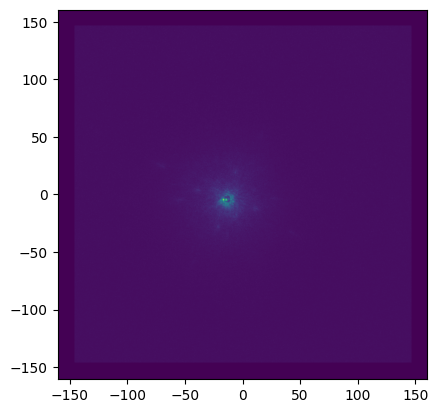

In [336]:
imshow_field(img)

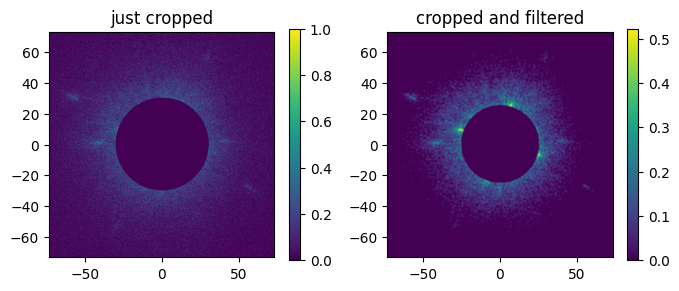

In [337]:
#the old way
plt.figure(figsize=(8,3))
plt.subplot(1,2,1)
imshow_field(ADC.crop_image(img,extent=512))
plt.title('just cropped')
plt.colorbar()
plt.subplot(1,2,2)
plt.title('cropped and filtered')
imshow_field(ADC.filter_image(ADC.crop_image(img,mask_diam=50,extent=512)))
plt.colorbar()

In [338]:
from scipy import ndimage

#new hpf?
def hpf(data,sigma):
    return Field((data.shaped - ndimage.gaussian_filter(data.shaped,sigma)).ravel(),data.grid)

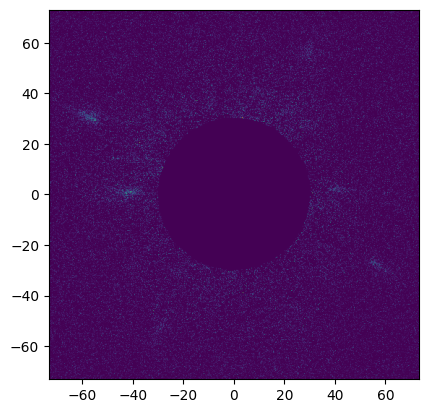

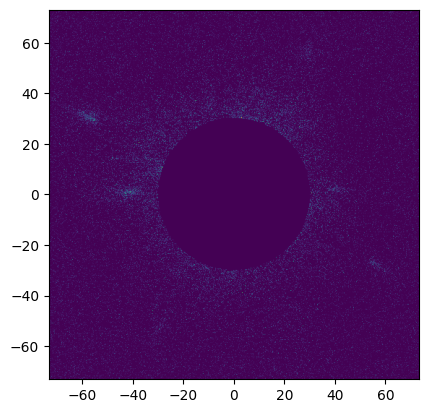

In [339]:
cropped = ADC.crop_image(img,extent=512,mask_diam=60)

sigmas = np.array([50,100])

for sigma in sigmas:
    hp_filtered = hpf(img,sigma)
    plt.figure()
    imshow_field(ADC.crop_image(hp_filtered,extent=512))
    plt.show()

In [340]:
hp_filtered = hpf(img,50)
img = ADC.crop_image(hp_filtered,extent=512,mask_diam=40)
#img = ADC.crop_image(img,extent=512,mask_diam=40)

[65.05487805  0.        ]


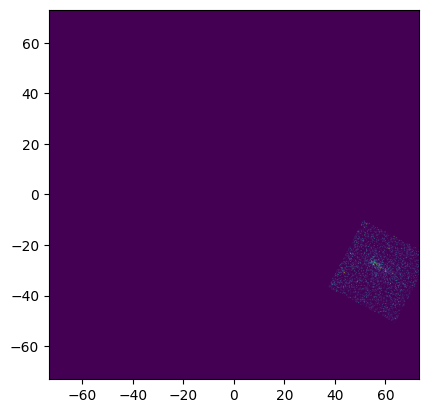

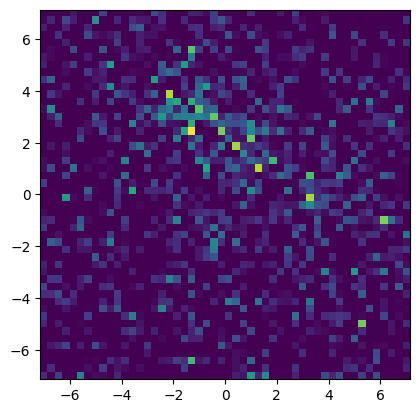

In [341]:
#what if i cut out the speckles first and then filtered?
#cut out the speckle window
speckle_number = 1
#locate the general area of the speckle
extent=30
speckle_coords = np.array([[0, ADC.grating_freq * ADC.normalized_wavelength],[ADC.grating_freq * ADC.normalized_wavelength,0],[0, -ADC.grating_freq * ADC.normalized_wavelength],[-ADC.grating_freq * ADC.normalized_wavelength,0]])
speckle_center = speckle_coords[speckle_number]
print(speckle_center)

#cut out the speckle area
rect = make_rotated_aperture(make_rectangular_aperture(size=(extent,extent), center=speckle_coords[speckle_number]), np.deg2rad(-grating_angle))(img.grid)
speckle_img = rect * img

#find the center of intensity of the speckle area and window the image around that center
center_of_intensity = np.array([sum(speckle_img*speckle_img.grid.x)/sum(speckle_img),sum(speckle_img*speckle_img.grid.y)/sum(speckle_img)])
window_size=50
new_img = ADC.window_field(img,[center_of_intensity[0],center_of_intensity[1]],window_size,window_size)

#tada!
imshow_field(speckle_img)
plt.figure()
imshow_field(new_img)

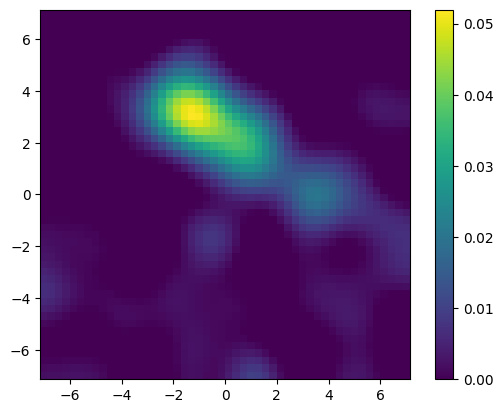

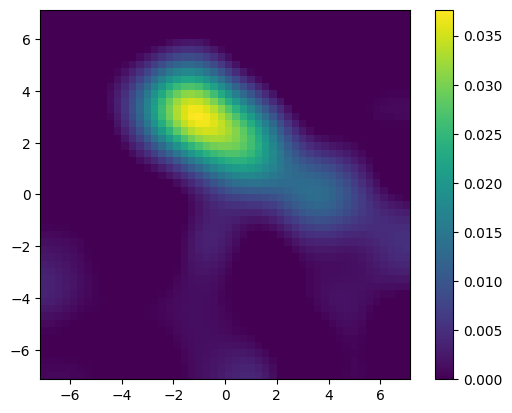

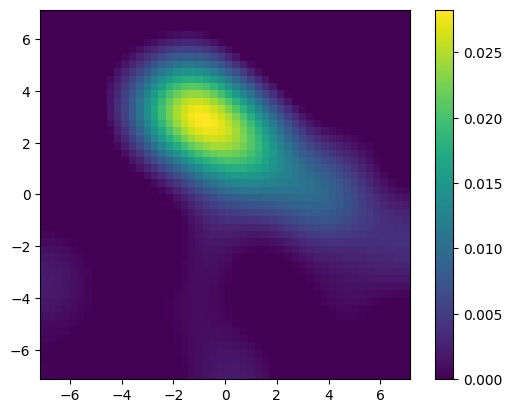

In [342]:
sigmas = np.array([3,4,5])

for sigma in sigmas:
    hp_small = hpf(new_img,sigma=10)
    lp_small = hp_small - hpf(hp_small,sigma)
    lp_small -= np.median(lp_small)
    lp_small[lp_small < 0 ] = 0
    plt.figure()
    imshow_field(lp_small)
    plt.colorbar()
    plt.show()

[ 0.         65.05487805]


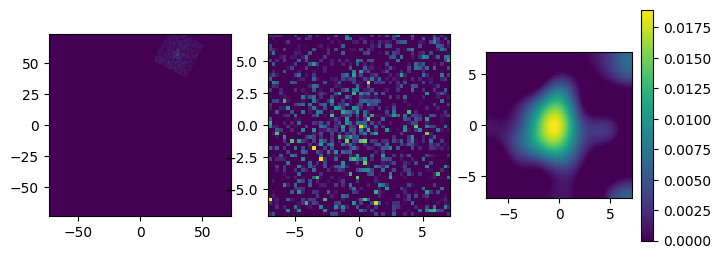

[65.05487805  0.        ]


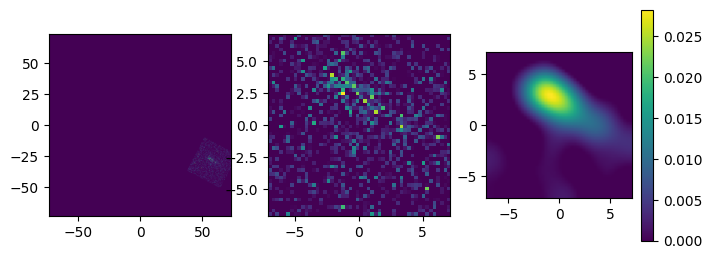

[  0.         -65.05487805]


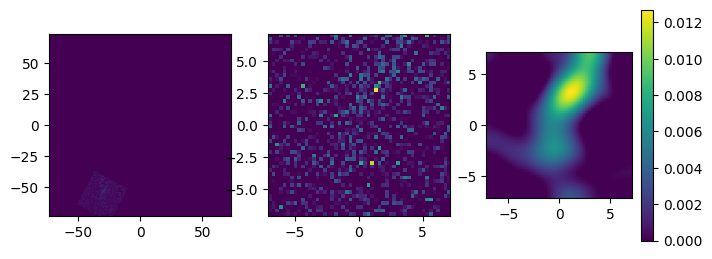

[-65.05487805   0.        ]


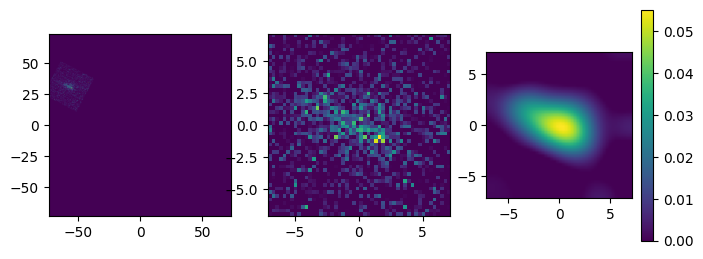

In [343]:
#and it looks like the winner is the combination of (high,low) = (10,5), alongside a median subtract
for i in range(4):
    speckle_number = i
    #locate the general area of the speckle
    extent=30
    speckle_coords = np.array([[0, ADC.grating_freq * ADC.normalized_wavelength],[ADC.grating_freq * ADC.normalized_wavelength,0],[0, -ADC.grating_freq * ADC.normalized_wavelength],[-ADC.grating_freq * ADC.normalized_wavelength,0]])
    speckle_center = speckle_coords[speckle_number]
    print(speckle_center)

    #cut out the speckle area
    rect = make_rotated_aperture(make_rectangular_aperture(size=(extent,extent), center=speckle_coords[speckle_number]), np.deg2rad(-grating_angle))(img.grid)
    speckle_img = rect * img

    #find the center of intensity of the speckle area and window the image around that center
    center_of_intensity = np.array([sum(speckle_img*speckle_img.grid.x)/sum(speckle_img),sum(speckle_img*speckle_img.grid.y)/sum(speckle_img)])
    window_size=50
    new_img = ADC.window_field(img,[center_of_intensity[0],center_of_intensity[1]],window_size,window_size)

    hp_sigma = 10
    lp_sigma = 5
    hp = hpf(new_img,hp_sigma)
    lp = hp - hpf(hp,lp_sigma)
    lp -= np.median(lp)
    lp[lp < 0 ] = 0
    new_img_filtered = lp

    #tada!
    plt.figure(figsize=(8,3))
    plt.subplot(1,3,1)
    imshow_field(speckle_img)
    plt.subplot(1,3,2)
    imshow_field(new_img)
    plt.subplot(1,3,3)
    imshow_field(new_img_filtered)
    plt.colorbar()
    plt.show()